In [6]:
import json

import matplotlib.pyplot as plt
import numpy as np

from modules import apodization

In [7]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [8]:
params = load_parameters('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/001_params_angles.json')

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling


Effective array length:  0.005000197722239797 first_transducer:  20 transducers_in_effective_array:  51


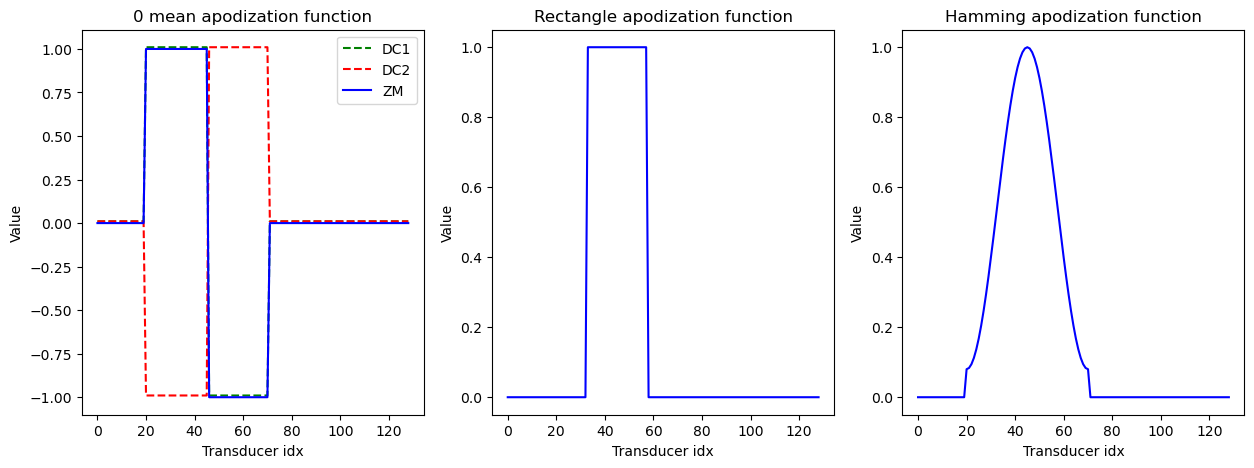

In [9]:
effective_array_length, transducers_in_effective_array, first_transducer = apodization.find_object_effective_aperture(200*2.25e-5, 1331*0.0095/3161, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])
print("Effective array length: ", effective_array_length, "first_transducer: ", first_transducer, "transducers_in_effective_array: ", transducers_in_effective_array)

apodization_zm = apodization.apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_dc1 = apodization.apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_dc2 = apodization.apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_rectangle = apodization.apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"], 0.01)
apodization_hamming = apodization.apodization_wrapper("hamming", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 1, params["array"]["pitch"], 0.01)

fig, ax = plt.subplots(1,3, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')

ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')

ax[2].plot(pos, apodization_hamming, color='b')
ax[2].set_title('Hamming apodization function')
ax[2].set_xlabel('Transducer idx')
ax[2].set_ylabel('Value')

plt.show()

In [10]:
apodization_hamming

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.08      , 0.08363411, 0.09446482, 0.11232132, 0.13692203,
       0.16787902, 0.20470412, 0.24681661, 0.29355241, 0.34417452,
       0.39788468, 0.4538359 , 0.51114588, 0.56891086, 0.62621994,
       0.68216939, 0.73587692, 0.7864956 , 0.8332272 , 0.87533481,
       0.9121544 , 0.94310536, 0.96769961, 0.98554932, 0.99637301,
       1.        , 0.99637309, 0.98554947, 0.96769983, 0.94310564,
       0.91215474, 0.8753352 , 0.83322765, 0.78649609, 0.73587744,
       0.68216994, 0.62622051, 0.56891144, 0.51114646, 0.45383647,
       0.39788523, 0.34417505, 0.29355289, 0.24681705, 0.20470451,
       0.16787936, 0.13692231, 0.11232153, 0.09446496, 0.08363419,
       0.08      , 0.        , 0.        , 0.        , 0.     